In [48]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

In [49]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(device)

cuda


In [50]:
import os, torch
  
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU      : {props.name}")
    print(f"VRAM     : {props.total_memory / 1e9:.2f} GB")
elif torch.backends.mps.is_available():
    print("GPU      : Apple Silicon (MPS)")
else:
    print("GPU      : Không có (chạy CPU)")

print(f"CPU cores: {os.cpu_count()}")

GPU      : NVIDIA L4
VRAM     : 23.66 GB
CPU cores: 12


In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Data preprocess

In [52]:
data_path = "/content/drive/MyDrive/Cifar-100/data"

MEAN = (0.5071, 0.4867, 0.4408)
STD  = (0.2675, 0.2565, 0.2761)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.2)),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

trainset = torchvision.datasets.CIFAR100(
    root=data_path,
    train=True,
    download=False,
    transform=train_transform
)

trainloader = DataLoader(
    trainset,
    batch_size=128,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
    drop_last=True,
)

testset = torchvision.datasets.CIFAR100(
    root=data_path,
    train=False,
    download=False,
    transform=test_transform
)

testloader = DataLoader(
    testset,
    batch_size=1024,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)

In [53]:
images, labels = next(iter(trainloader))
print("Batch images shape:", images.shape)       # Kỳ vọng: torch.Size([128, 3, 32, 32])
print("Num classes       :", len(trainset.classes)) # Kỳ vọng: 100

Batch images shape: torch.Size([128, 3, 32, 32])
Num classes       : 100


### MODEL

In [54]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False), # Sửa stride=stride
                nn.BatchNorm2d(out_ch)
            )
        self.act_func = nn.GELU()
    
    def forward(self, x):
        return self.act_func(self.main(x) + self.shortcut(x)) # Truyền x vào cả 2 nhánh


class CustomModel(nn.Module):
    def __init__(self, in_ch=3, out_ch=32, num_classes=100):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch * 2, kernel_size=3, padding=1, stride=1, bias=False), # (64, 32, 32)
            nn.BatchNorm2d(out_ch * 2),
            nn.GELU()
        )
        self.layer1 = nn.Sequential(
            ResidualBlock(out_ch * 2, out_ch * 2, 1), # (64, 32, 32)
            ResidualBlock(out_ch * 2, out_ch * 2, 1)
        )
        self.layer2 = nn.Sequential(
            ResidualBlock(out_ch * 2, out_ch * 4, 2), # (128, 16, 16)
            ResidualBlock(out_ch * 4, out_ch * 4, 1),
        )
        self.layer3 = nn.Sequential(
            ResidualBlock(out_ch * 4, out_ch * 8, 2), # (256, 8, 8)
            ResidualBlock(out_ch * 8, out_ch * 8, 1)
        )
        self.layer4 = nn.Sequential(
            ResidualBlock(out_ch * 8, out_ch * 16, 2), # (512, 4, 4)
            ResidualBlock(out_ch * 16, out_ch * 16, 1)
        )
        self.mlp = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(out_ch * 16, num_classes) # 512 -> 100
        )
        
    def forward(self, x):
        x = self.block(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.mlp(x)
    
model = CustomModel().to(device)

###  Sanity check & parameters

In [55]:
# 1. Sanity Check: Tạo tensor giả lập (Batch=5, Channel=1, Height=28, Width=28)
dummy_input = torch.randn(5, 3, 32, 32).to(device)

model.eval()
with torch.no_grad():
    output = model(dummy_input)

print(f"Input shape : {dummy_input.shape}")
print(f"Output shape: {output.shape}")  # Kỳ vọng: torch.Size([5, 10])

# 2. Check Parameters (Tổng số tham số & Tham số có thể huấn luyện)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Input shape : torch.Size([5, 3, 32, 32])
Output shape: torch.Size([5, 100])
Total parameters    : 11,220,132
Trainable parameters: 11,220,132


### Loss, criterion, evaluate function

In [56]:
epochs = 100

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [57]:
def evaluate(model, testloader, criterion):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
                outputs = model(images)
                loss = criterion(outputs, labels)

            test_loss += loss.item()
            labels_predicted = torch.argmax(outputs, 1)
            total += labels.size(0)
            correct += (labels_predicted == labels).sum().item()
    accuracy = 100 * correct / total
    test_loss = test_loss / len(testloader)
    return test_loss, accuracy

### Train Model

In [58]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
best_acc = 0.0
save_path = "/content/drive/MyDrive/Cifar-100/best_resnet18_v4.pth"

In [59]:
import time

start = time.time()
for images, labels in trainloader:
    images, labels = images.to(device), labels.to(device)
print(f"Thời gian load & chuyển dữ liệu 1 epoch: {time.time() - start:.2f}s")

Thời gian load & chuyển dữ liệu 1 epoch: 6.06s


In [60]:
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in trainloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
            outputs = model(images)
            loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        labels_predicted = torch.argmax(outputs, 1)
        total += labels.size(0)
        running_correct += (labels_predicted == labels).sum().item()

    scheduler.step()

    epoch_accuracy = 100 * running_correct / total
    epoch_loss = running_loss / len(trainloader)
    test_loss, test_accuracy = evaluate(model, testloader, criterion)

    if test_accuracy > best_acc:
        best_acc = test_accuracy
        torch.save(model.state_dict(), save_path)

    current_lr = scheduler.get_last_lr()[0]
    print(
        f"Epoch [{epoch + 1:3d}/{epochs}] | LR: {current_lr:.5f} | "
        f"Loss: {epoch_loss:.4f}, Acc: {epoch_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f}, Test Acc: {test_accuracy:.2f}% (Best: {best_acc:.2f}%)"
    )

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [  1/100] | LR: 0.09998 | Loss: 4.1760, Acc: 7.44% | Test Loss: 3.8800, Test Acc: 11.83% (Best: 11.83%)
Epoch [  2/100] | LR: 0.09990 | Loss: 3.7914, Acc: 14.17% | Test Loss: 3.6179, Test Acc: 18.59% (Best: 18.59%)
Epoch [  3/100] | LR: 0.09978 | Loss: 3.4990, Acc: 20.68% | Test Loss: 3.3564, Test Acc: 24.20% (Best: 24.20%)
Epoch [  4/100] | LR: 0.09961 | Loss: 3.2312, Acc: 26.79% | Test Loss: 3.0276, Test Acc: 32.09% (Best: 32.09%)
Epoch [  5/100] | LR: 0.09938 | Loss: 2.9645, Acc: 33.64% | Test Loss: 2.8792, Test Acc: 35.83% (Best: 35.83%)
Epoch [  6/100] | LR: 0.09911 | Loss: 2.7732, Acc: 38.92% | Test Loss: 2.6766, Test Acc: 41.67% (Best: 41.67%)
Epoch [  7/100] | LR: 0.09880 | Loss: 2.6192, Acc: 42.97% | Test Loss: 2.6513, Test Acc: 43.02% (Best: 43.02%)
Epoch [  8/100] | LR: 0.09843 | Loss: 2.4966, Acc: 46.56% | Test Loss: 2.4383, Test Acc: 48.00% (Best: 48.00%)
Epoch [  9/100] | LR: 0.09801 | Loss: 2.4053, Acc: 49.47% | Test Loss: 2.3531, Test Acc: 51.22% (Best: 51.22%)
Ep

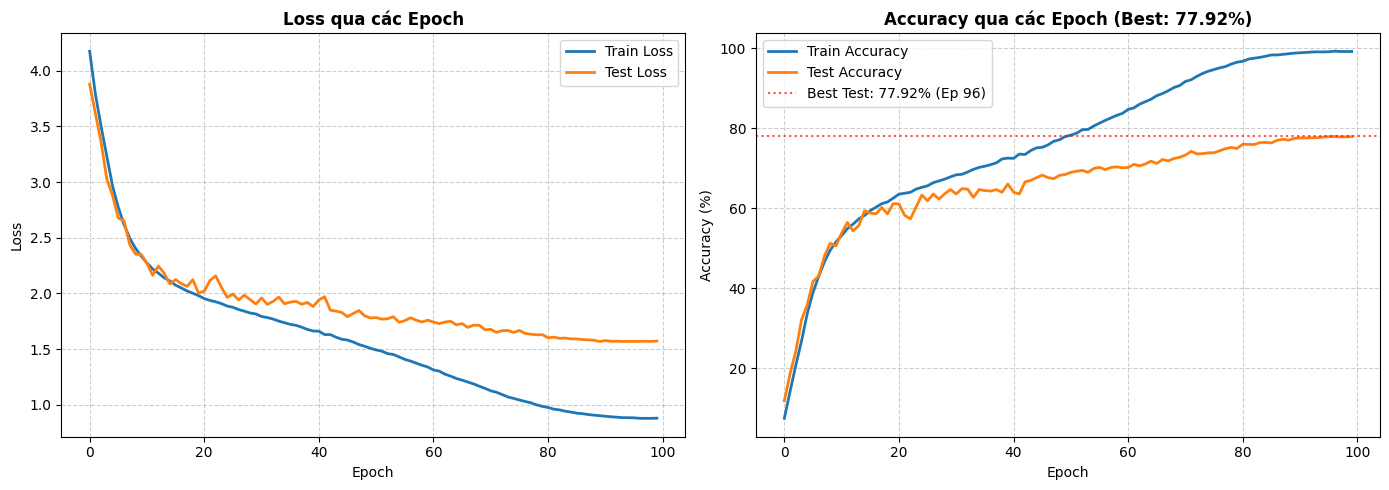

Đã lưu biểu đồ thành công tại: /content/drive/MyDrive/Cifar-100/cifar100_v4_resnet18_sgd.png


In [61]:
import matplotlib.pyplot as plt

def save_training_plot(train_losses, test_losses, train_accs, test_accs, filename="cifar100_v1.png"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Biểu đồ 1: Loss
    axes[0].plot(train_losses, label="Train Loss", linewidth=2)
    axes[0].plot(test_losses, label="Test Loss", linewidth=2)
    axes[0].set_title("Loss qua các Epoch", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.6)
    
    # Biểu đồ 2: Accuracy
    best_acc = max(test_accs)
    best_epoch = test_accs.index(best_acc)
    
    axes[1].plot(train_accs, label="Train Accuracy", linewidth=2)
    axes[1].plot(test_accs, label="Test Accuracy", linewidth=2)
    axes[1].axhline(best_acc, color="red", linestyle=":", alpha=0.7, label=f"Best Test: {best_acc:.2f}% (Ep {best_epoch})")
    axes[1].set_title(f"Accuracy qua các Epoch (Best: {best_acc:.2f}%)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.6)
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight") # Lưu file ảnh trước khi show()
    plt.show()
    print(f"Đã lưu biểu đồ thành công tại: {filename}")

# Cách gọi hàm (Mỗi lần đổi kiến trúc chỉ cần đổi tên file):
save_training_plot(
    train_losses, test_losses, train_accuracies, test_accuracies,
    filename="/content/drive/MyDrive/Cifar-100/cifar100_v4_resnet18_sgd.png"
)